# 03 – Approach A2: Fine-Tuning Pretrained DistilBERT (plain truncation)
**DS5007 NLP · Assignment 2 · Extractive QA on SQuAD 1.1**

**Idea.** Replace the randomly initialised encoder of A1 with **pretrained DistilBERT** and keep everything else identical: the same tokenizer vocabulary, start/end heads, loss, training loop, span search and metrics. Inputs are **truncated** to 384 tokens (one input per question). Sliding windows are added in notebook 04 (A3).

**Why pretrained representations should help (motivation).** A1 had to learn English from 88k questions and reached only ≈20 F1. DistilBERT starts with knowledge learned from ≈3.3 billion words (BooksCorpus + English Wikipedia). Through masked-language-model pretraining (distilled from BERT) its layers already encode word meaning, synonyms, syntax, coreference and a lot of world knowledge. Fine-tuning only has to learn *where answers are*, which the 88k SQuAD questions are sufficient for.

**DistilBERT** (Sanh et al., 2019) is a 6-layer student trained to imitate the 12-layer BERT-base teacher (soft-target distillation loss + masked-LM loss + cosine loss on hidden states). It keeps ≈97% of BERT's language-understanding performance with 40% fewer parameters and is ≈60% faster.

| | A1 scratch | **A2 DistilBERT** |
|---|---|---|
| Layers / hidden size / heads | 4 / 256 / 4 | 6 / 768 / 12 |
| FFN size | 1024 | 3072 |
| Embeddings | token + position + segment, random | token + position, **pretrained** (no segment embeddings) |
| Parameters | 11.1M | 66.4M (1,538 new) |
| Learning rate | 5e-4 | 5e-5 (fine-tuning must not destroy pretrained knowledge) |

## 1. Setup and data: truncated inputs
One input per question: `[CLS] question [SEP] first context tokens [SEP]`, at most 384 tokens. If the answer lies beyond the cut, the input is labelled `[CLS]` during training and the question cannot be answered at inference.

In [1]:
# Environment: on Google Colab, mount Drive and work inside the uploaded project folder; locally nothing to do.
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/EQA_Assignment"      # <- path of the uploaded project folder
    os.chdir(os.path.join(PROJECT_DIR, "notebooks"))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers>=4.40", "datasets", "gradio"])
sys.path.insert(0, os.path.abspath(".."))                     # make eqa_lib.py (project root) importable

import eqa_lib as eqa          # imported first: it initialises OpenSSL before torch/pyarrow (Windows workaround)
import json, time, re, collections, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)
ENV = eqa.setup()

python         : 3.14.6
torch          : 2.14.1+cu126
transformers   : 5.19.0
numpy          : 2.4.6
pandas         : 3.0.3
device         : cuda
gpu            : NVIDIA GeForce RTX 4050 Laptop GPU
gpu_memory_gb  : 6.0
cuda           : 12.6
amp_dtype      : torch.bfloat16
seed           : 42
quick_run      : False
force_retrain  : False
project_root   : C:\Users\kiran\NLP Assignment 2\EQA_Assignment


In [2]:
RUN = "distilbert_baseline"
RC = dict(arch="pretrained", encoder="distilbert-base-uncased",
          input_strategy="truncation", max_length=384, doc_stride=None,
          lr=5e-5, batch_size=16, epochs=2, warmup_ratio=0.1, weight_decay=0.01, max_grad_norm=1.0,
          evals_per_epoch=2, patience=2, train_fraction=1.0)
if eqa.QUICK_RUN:
    RC["epochs"], RC["evals_per_epoch"] = 1, 1
print(json.dumps(RC, indent=2))

train_raw, val_df, _ = eqa.load_squad()
train_df, _ = eqa.clean_training_data(train_raw)
tokenizer = eqa.get_tokenizer()
train_feats, train_stats = eqa.prepare_features(train_df, tokenizer, RC["max_length"], sliding_window=False)
val_feats, val_stats = eqa.prepare_features(val_df, tokenizer, RC["max_length"], sliding_window=False, keep_offsets=True)
display(pd.DataFrame({"train": train_stats, "validation": val_stats}).drop(index="mismatch_examples"))
print(f"Training inputs whose answer was cut off by truncation (labelled [CLS]): {train_stats.get('windows_without_answer', 0)}")
print(f"Validation questions whose answer is beyond token 384 (unanswerable for A2): {val_stats['examples_whose_answer_is_unreachable']}")

{
  "arch": "pretrained",
  "encoder": "distilbert-base-uncased",
  "input_strategy": "truncation",
  "max_length": 384,
  "doc_stride": null,
  "lr": 5e-05,
  "batch_size": 16,
  "epochs": 2,
  "warmup_ratio": 0.1,
  "weight_decay": 0.01,
  "max_grad_norm": 1.0,
  "evals_per_epoch": 2,
  "patience": 2,
  "train_fraction": 1.0
}
[info] `datasets` not usable here (ImportError: DLL load failed while importing _xxhash: An Application Control policy has block...)
[info] Falling back to the identical parquet files on the Hugging Face Hub.


Loaded from huggingface_hub: rajpurkar/squad (plain_text parquet): 87,599 training / 10,570 validation examples


,train,validation
questions_truncated,0,0
windows_with_answer,87523,10536
span_exact_match,87298,10504
span_mismatch,225,32
windows_without_answer,76,34
examples,87599,10570
features,87599,10570
examples_with_answer_in_some_window,87523,10536
examples_whose_answer_is_unreachable,76,34


Training inputs whose answer was cut off by truncation (labelled [CLS]): 76
Validation questions whose answer is beyond token 384 (unanswerable for A2): 34


## 2. Model: pretrained encoder + our span heads
`TransformerQAModel` wraps any Hugging Face encoder loaded with `AutoModel.from_pretrained` (the bare encoder, **not** a QA model or pipeline) and adds the **same `SpanHeads`** as A1. Its output vectors $h_i \in \mathbb{R}^{768}$ feed $s_i = w_s^\top h_i + b_s$ and $e_j = w_e^\top h_j + b_e$, followed by the softmax and loss $\mathcal{L} = -\frac12[\log P_{start}(y_s) + \log P_{end}(y_e)]$. Since DistilBERT has no segment embeddings, `token_type_ids` are not passed to it. The model still knows which tokens are question and which are context from the `[SEP]` token and from position.

In [3]:
eqa.show_source(eqa.TransformerQAModel, eqa.build_pretrained_model)
model = eqa.build_model(RC).to(eqa.DEVICE)
enc = model.encoder
groups = {"embeddings (token + position)": enc.embeddings, "6 Transformer layers": enc.transformer,
          "span heads (new, random init)": model.heads}
param_tbl = pd.DataFrame({"parameters": {k: eqa.count_parameters(m) for k, m in groups.items()}})
param_tbl.loc["TOTAL"] = eqa.count_parameters(model)
display(param_tbl)
print(f"config: {enc.config.n_layers} layers, dim {enc.config.dim}, {enc.config.n_heads} heads, FFN {enc.config.hidden_dim}, "
      f"max positions {enc.config.max_position_embeddings} | passes token_type_ids: {model.uses_token_type_ids}")

batch = eqa.collate([eqa.QAFeatureDataset(train_feats)[i] for i in range(8)]); batch.pop("feature_idx")
batch = {k: v.to(eqa.DEVICE) for k, v in batch.items()}
model.eval()
with torch.no_grad(), eqa.autocast_ctx():
    out = model(**batch)
print(f"input {tuple(batch['input_ids'].shape)} -> start/end logits {tuple(out['start_logits'].shape)} | "
      f"loss before fine-tuning {out['loss'].item():.3f} (heads are untrained)")
del model

```python
class TransformerQAModel(nn.Module):
    """Pretrained Transformer encoder (DistilBERT / BERT) + the SAME start/end span heads as approach A1.

    The encoder weights come from Hugging Face (`AutoModel.from_pretrained`); only the two linear heads
    (2 x (768 + 1) = 1,538 parameters) are new. Everything is fine-tuned end to end with our own training loop.
    """

    def __init__(self, encoder, dropout=0.1):
        super().__init__()
        self.encoder = encoder
        self.heads = SpanHeads(encoder.config.hidden_size, dropout)
        # DistilBERT has no segment (token type) embeddings -> only pass token_type_ids to encoders that accept them
        self.uses_token_type_ids = "token_type_ids" in inspect.signature(encoder.forward).parameters

    def forward(self, input_ids, attention_mask, token_type_ids=None, start_positions=None, end_positions=None):
        kwargs = {"input_ids": input_ids, "attention_mask": attention_mask}
        if self.uses_token_type_ids and token_type_ids is not None:
            kwargs["token_type_ids"] = token_type_ids
        hidden = self.encoder(**kwargs).last_hidden_state            # (B, L, 768) contextual representations
        return self.heads(hidden, attention_mask, start_positions, end_positions)

```

```python
def build_pretrained_model(rc: dict, encoder_config=None):
    """Pretrained weights from the Hub (training) or an empty encoder from a saved config (loading a checkpoint)."""
    from transformers import AutoModel
    encoder = (AutoModel.from_config(encoder_config) if encoder_config is not None
               else AutoModel.from_pretrained(rc["encoder"]))
    return TransformerQAModel(encoder, dropout=rc.get("head_dropout", 0.1))

```

,parameters
embeddings (token + position),23835648
6 Transformer layers,42527232
"span heads (new, random init)",1538
TOTAL,66364418


config: 6 layers, dim 768, 12 heads, FFN 3072, max positions 512 | passes token_type_ids: False


input (8, 271) -> start/end logits (8, 271) | loss before fine-tuning 5.310 (heads are untrained)


## 3. Fine-tuning
Same `eqa.train_model` as A1: AdamW (weight decay 0.01), 10% linear warm-up then linear decay, gradient clipping 1.0, bf16 mixed precision, length-grouped dynamic padding. Validation EM/F1 is computed **every half epoch** on all 10,570 validation questions, the best-F1 checkpoint is saved to `models/distilbert_baseline/`, and early stopping uses patience 2. Hyper-parameters follow the standard DistilBERT SQuAD recipe (lr 5e-5, 2 epochs), with batch 16 to fit the 6 GB GPU.

In [4]:
model, hist = eqa.train_model(RUN, RC, train_feats, val_feats, val_df, model_dir=eqa.PATHS.models / RUN)

=== distilbert_baseline: 66.36M params | 87,599 questions -> 87,599 inputs | 2 epochs x 5475 steps (batch 16, lr 5e-05) ===


[distilbert_baseline] epoch 1/2 step   547/5475 | train loss 3.6414 | lr 2.50e-05 |   0.9 min, ETA  17.0 min


[distilbert_baseline] epoch 1/2 step  1094/5475 | train loss 1.8272 | lr 5.00e-05 |   1.8 min, ETA  16.1 min


[distilbert_baseline] epoch 1/2 step  1641/5475 | train loss 1.5112 | lr 4.72e-05 |   2.7 min, ETA  15.2 min


[distilbert_baseline] epoch 1/2 step  2188/5475 | train loss 1.3985 | lr 4.45e-05 |   3.6 min, ETA  14.3 min


[distilbert_baseline] epoch 1/2 step  2735/5475 | train loss 1.3728 | lr 4.17e-05 |   4.5 min, ETA  13.5 min


... (16 outputs left out)

[distilbert_baseline] epoch 2/2 step  4918/5475 | train loss 0.7942 | lr 2.83e-06 |  18.4 min, ETA   0.9 min


[distilbert_baseline] epoch 2/2 step  5465/5475 | train loss 0.7781 | lr 5.07e-08 |  19.4 min, ETA   0.0 min


[distilbert_baseline] >>> eval @ epoch 2.00: train loss 0.8071 | val loss 1.0949 | EM 78.06 | F1 85.89  (new best)


[distilbert_baseline] done: 19.7 min (18.5 min training, 1.2 min validation) | best F1 85.89 | peak GPU memory 2.33 GB


## 4. Results
### 4.1 Training and validation curves

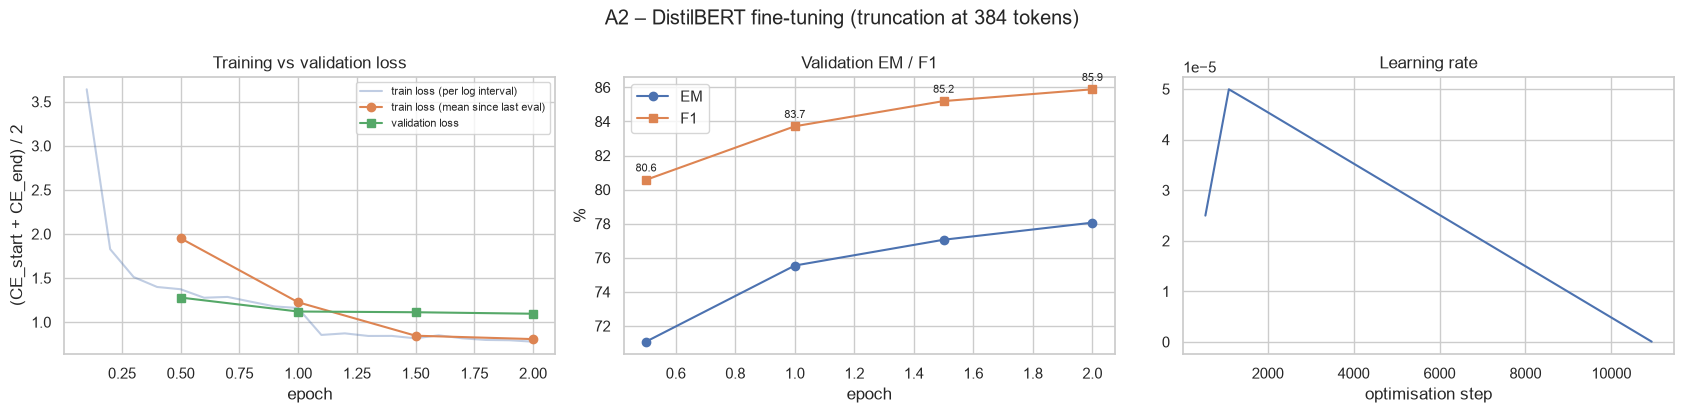

,epoch,train_loss,val_loss,exact_match,f1,elapsed_min
0,0.5,1.950,1.278,71.079,80.573,4.772
1,1.0,1.225,1.120,75.544,83.715,9.633
2,1.5,0.845,1.112,77.058,85.193,14.620
3,2.0,0.807,1.095,78.061,85.885,19.699


In [5]:
eqa.plot_history(hist, "A2 – DistilBERT fine-tuning (truncation at 384 tokens)")
eqa.savefig("03_A2_training_curves")
display(pd.DataFrame(hist["evals"])[["epoch", "train_loss", "val_loss", "exact_match", "f1", "elapsed_min"]].round(3))

In [6]:
ev = eqa.evaluate_model(model, val_feats, val_df)
print(f"A2 best checkpoint (epoch {hist['best']['epoch']:.1f}) on the full validation set ({len(val_df):,} questions):")
print(f"   Exact Match = {ev['exact_match']:.2f}   F1 = {ev['f1']:.2f}   validation loss = {ev['val_loss']:.4f}")
print(f"   training time {hist['train_time_min']:.1f} min ({hist['pure_train_time_min']:.1f} min excluding validation), "
      f"peak GPU memory {hist['peak_gpu_mem_gb']:.2f} GB")
print(f"   inference: {ev['forward_seconds']:.1f} s for {ev['n_features']:,} inputs ({ev['features_per_sec']:.0f} inputs/s) | "
      f"checkpoint {hist['model_size_mb']:.0f} MB | {hist['n_params'] / 1e6:.1f}M parameters")
row = eqa.experiment_row(RUN, "A2 DistilBERT (truncation)", hist, ev, "truncation", RC["max_length"], None)
logs = eqa.log_experiment(row)
eqa.save_json(ev["predictions"], eqa.PATHS.results / f"predictions_{RUN}.json")
ev["details"].to_csv(eqa.PATHS.results / f"details_{RUN}.csv", index=False)
cols = ["approach", "params_M", "epochs_run", "pure_train_time_min", "peak_train_gpu_mem_GB", "inference_inputs_per_s", "EM", "F1"]
print("\nComparison with the approaches trained so far (results/experiment_logs.csv):")
logs[cols].round(2)

A2 best checkpoint (epoch 2.0) on the full validation set (10,570 questions):
   Exact Match = 78.06   F1 = 85.89   validation loss = 1.0949
   training time 19.7 min (18.5 min excluding validation), peak GPU memory 2.33 GB
   inference: 14.2 s for 10,570 inputs (744 inputs/s) | checkpoint 265 MB | 66.4M parameters

Comparison with the approaches trained so far (results/experiment_logs.csv):


,approach,params_M,epochs_run,pure_train_time_min,peak_train_gpu_mem_GB,inference_inputs_per_s,EM,F1
0,A1 Transformer from scratch,11.11,7.0,12.25,1.32,2232.59,10.53,20.09
1,A2 DistilBERT (truncation),66.36,2.0,18.52,2.33,743.89,78.06,85.89


### 4.2 Breakdown by question type, and examples

outcome
exact      78.1
partial    13.7
wrong       8.2 



,n,EM_A2,F1_A2,EM_A1,F1_A1
qtype,,,,,
what,6021,77.1,85.3,6.4,15.4
who,1185,84.7,89.1,9.4,22.0
when,713,89.9,92.9,35.1,45.1
which,698,80.4,86.2,8.9,17.1
how many,642,85.0,89.9,30.8,36.5
where,476,71.0,82.4,5.9,13.7
how,432,61.3,77.2,6.5,18.5
why,155,48.4,73.8,3.9,33.0
how much,154,81.8,87.6,26.0,38.5


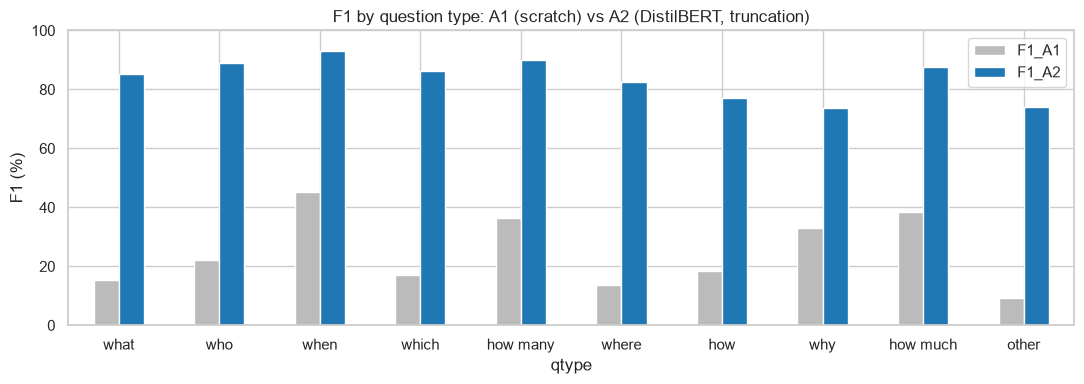

--- PARTIAL examples ---
Q: What was the last Doctor Who episode that Dudley Simpson wrote music for?
   gold: ['The Horns of Nimon'] | predicted: 'Planet of Giants' (F1=0.33, conf=0.90)
Q: What is preschool required for?
   gold: ['a key requirement for admission to Standard One (First Grade)', 'admission to Standard One'] | predicted: 'admission to Standard One (First Grade)' (F1=0.80, conf=0.51)
Q: In what sector are jobs beginning to decrease?
   gold: ['manufacturing'] | predicted: 'manufacturing sector to the service' (F1=0.40, conf=0.23)
Q: Who decides how land or property is allowed to be used?
   gold: ['Scottish Government.', 'Committees', 'Private Bill Committees'] | predicted: 'A further type of committee is normally set up to scrutinise private bills submitted to the Scottish Parliament' (F1=0.11, conf=0.06)
--- WRONG examples ---
Q: What type of missions were approved by Mueller after the incident?
   gold: ['sequence', 'manned lunar landing.', 'had to be successfully acc

In [7]:
d = ev["details"].merge(val_df[["id", "question", "answer_texts"]], on="id")
d["qtype"] = d["question"].map(eqa.question_type)
d["outcome"] = np.where(d["em"] == 1, "exact", np.where(d["f1"] > 0, "partial", "wrong"))
print(d["outcome"].value_counts(normalize=True).mul(100).round(1).to_string(), "\n")
a1 = pd.read_csv(eqa.PATHS.results / "details_transformer_scratch.csv")[["id", "em", "f1"]].rename(columns={"em": "em_A1", "f1": "f1_A1"})
dd = d.merge(a1, on="id", how="left")
by_q = dd.groupby("qtype").agg(n=("id", "size"), EM_A2=("em", "mean"), F1_A2=("f1", "mean"), EM_A1=("em_A1", "mean"), F1_A1=("f1_A1", "mean"))
by_q[["EM_A2", "F1_A2", "EM_A1", "F1_A1"]] *= 100
display(by_q.sort_values("n", ascending=False).round(1))
fig, ax = plt.subplots(figsize=(11, 4))
by_q.sort_values("n", ascending=False)[["F1_A1", "F1_A2"]].plot.bar(ax=ax, rot=0, color=["#bbbbbb", "#1f77b4"])
ax.set_ylabel("F1 (%)"); ax.set_title("F1 by question type: A1 (scratch) vs A2 (DistilBERT, truncation)"); ax.set_ylim(0, 100)
eqa.savefig("03_A2_vs_A1_by_question_type")
for outcome in ("partial", "wrong"):
    print(f"--- {outcome.upper()} examples ---")
    for r in d[d["outcome"] == outcome].sample(min(4, (d["outcome"] == outcome).sum()), random_state=eqa.SEED).itertuples():
        print(f"Q: {r.question}\n   gold: {list(dict.fromkeys(r.answer_texts))} | predicted: {r.prediction!r} (F1={r.f1:.2f}, conf={r.confidence:.2f})")

### 4.3 The cost of truncation
Questions whose answer lies beyond the 384-token cut cannot be answered by A2. The model then returns the best-looking span from the part it *can* see. On SQuAD this affects few questions at 384 tokens; the effect at shorter lengths is studied in notebook 05 (Experiment D).

In [8]:
reachable = pd.Series([s > 0 for s in val_feats["start_positions"]], index=val_feats["example_idx"])
d["answer_in_input"] = d["example_idx"].map(reachable)
display(d.groupby("answer_in_input").agg(n=("id", "size"), EM=("em", "mean"), F1=("f1", "mean")).assign(EM=lambda x: 100 * x.EM, F1=lambda x: 100 * x.F1).round(2))
for r in d[~d["answer_in_input"]].head(3).itertuples():
    ctx = val_df.loc[val_df["id"] == r.id, "context"].iloc[0]
    print(f"Q: {r.question}\n   gold: {list(dict.fromkeys(r.answer_texts))} (starts at character {val_df.loc[val_df['id'] == r.id, 'answer_starts'].iloc[0][0]} of {len(ctx)})"
          f"\n   predicted from the visible part: {r.prediction!r}\n")

,n,EM,F1
answer_in_input,,,
False,34,8.82,18.26
True,10536,78.28,86.10


Q: What website are teachers using to sell their lesson plans?
   gold: ['TeachersPayTeachers.com'] (starts at character 2142 of 2166)
   predicted from the visible part: 'Merit pay systems'

Q: By separating faith and reason, what does Luther honor?
   gold: ['different epistemological spheres.', 'separate spheres of knowledge that each applies to', 'separate spheres of knowledge'] (starts at character 1796 of 1830)
   predicted from the visible part: 'the separate spheres of knowledge'

Q: How much of a voting majority must there be to effectively censure the Commission?
   gold: ['two-thirds majority', 'a two-thirds majority'] (starts at character 2742 of 3326)
   predicted from the visible part: 'ten times the voting weight in Parliament as citizens of the largest countries'



## 5. Discussion: why pretraining helps
**Results (measured above).** A2 reaches **EM 78.06 / F1 85.89** after 2 epochs, compared with **EM 10.53 / F1 20.09** for the Transformer trained from scratch (A1). That is **+67.5 EM and +65.8 F1 points** with the same data, heads, loss, training loop and metrics. Only the encoder and the input strategy differ, and at 384 tokens truncation hides just 0.3% of answers. Half an epoch of fine-tuning (≈44k questions seen once) already gives F1 80.6, four times A1's best after seven epochs.

**Why pretrained representations help.**
1. **Lexical semantics comes for free.** DistilBERT's embeddings and layers already know that *"introduce"* relates to *"introduced"*, that *"tributary"* relates to river names, and which words are synonyms. A1 had to learn this from 88k questions. The largest gains are on question types that need meaning-level matching: *what* (+70 F1), *which* (+69), *where* (+69). Types that A1 could partly solve with answer-type shortcuts (*when*, *how many*) gain less in relative terms.
2. **Syntax and phrase structure.** Pretraining teaches where noun phrases, names and clauses begin and end. Most remaining partial matches are boundary disagreements (*"manufacturing sector to the service"* vs *"manufacturing"*), not wrong regions. 78.1% of answers are exact, 13.7% partial and only 8.2% have no overlap.
3. **Contextual, bidirectional representations.** Each token vector depends on the whole question and context, so the start/end heads only need a linear read-out (1,538 new parameters).
4. **Better optimisation and generalisation.** Validation loss falls monotonically (1.28 → 1.09) with only a moderate train/validation gap (0.81 vs 1.09) and no overfitting within 2 epochs. A1 started overfitting after 3 epochs.

**Remaining errors.** The hardest types are *why* (EM 48.4, F1 73.8) and *how* (61.3 / 77.2). Their answers are long explanatory phrases with ambiguous boundaries, which shows as a large F1 − EM gap. Fully wrong answers are usually a distractor of the right type from the same paragraph: *"Carolina"* instead of *"Newton"*, *"the Neckar"* instead of *"the Moselle"* (another Rhine tributary).

**Cost of truncation at 384 tokens.** Only 34 of 10,570 validation questions (0.32%) have their answer beyond the cut. On those, A2 scores EM 8.8, and those correct answers happen only when another annotator's reference answer appears earlier in the paragraph. The other 10,536 questions score EM 78.3. Truncation therefore costs only ≈0.2 EM points at 384 tokens. The cost grows quickly at shorter lengths (notebook 01: only 79.7% of answers fit into 128 tokens), which A3 and Experiment D address.

**Computational cost.** 66.4M parameters (6× A1), a 265 MB checkpoint, 9.3 min of optimisation per epoch (A1: 1.75), 2.33 GB peak training memory and 744 inputs/s at inference (A1: ≈2,230/s). The accuracy gain is far larger than the 5× increase in training cost.